# IS 4487 Assignment 6: Data Cleaning with Airbnb Listings

In this assignment, you will:
- Load a raw Airbnb listings dataset
- Identify and resolve missing or inconsistent data
- Decide what data to drop, keep, or clean
- Save a clean dataset to use in Assignment 7

## Why This Matters

Data cleaning is one of the most important steps in any analysis — but it's often the least visible. Airbnb hosts, managers, and policy teams rely on clean data to make decisions. This assignment gives you experience cleaning raw data and justifying your choices so others can understand your process.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_06_data_cleaning.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

📌 The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.


## 1. Choose a City & Upload Your Dataset

📥 Follow these steps:

1. Go to: [https://insideairbnb.com/get-the-data/](https://insideairbnb.com/get-the-data/)
2. Choose a city you’re interested in.
3. Download the file named: **`listings.csv.gz`** under that city.
4. In your notebook:
   - Open the left sidebar
   - Click the folder icon 📁
   - Click the upload icon ⬆️ and choose your `listings.csv.gz` file
5. Use the file path `/content/listings.csv.gz` when loading your data.
6. Import standard libraries (`pandas`, `numpy`, `seaborn`, `matplotlib`)


In [19]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Configure inline plotting
%matplotlib inline

In [20]:
# Load your uploaded file (path "/content/listings.csv.gz")
import pandas as pd

df = pd.read_csv('/content/listings.csv.gz', compression='gzip', low_memory=False)
df.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,1188641052152277018,https://www.airbnb.com/rooms/1188641052152277018,20260615212226,2026-06-16,city scrape,Spacious unit at heart of SEA,"Located in the heart of Seattle, This is a stu...",NaN,https://a0.muscache.com/pictures/miso/Hosting-...,32542619,...,NaN,NaN,NaN,NaN,NaN,4,4,0,0,NaN
1,849077848951991421,https://www.airbnb.com/rooms/849077848951991421,20260615212226,2026-06-16,city scrape,"Blueground | Central District, gym & bbq, nr d...",Feel at home wherever you choose to live with ...,NaN,https://a0.muscache.com/pictures/prohost-api/H...,107434423,...,NaN,NaN,NaN,NaN,NaN,239,239,0,0,NaN
2,599205596133828323,https://www.airbnb.com/rooms/599205596133828323,20260615212226,2026-06-16,city scrape,purple room,simple room facing front yard in centrally lo...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,48441443,...,5.00,5.00,5.00,NaN,NaN,5,0,5,0,0.06
3,846763,https://www.airbnb.com/rooms/846763,20260615212226,2026-06-16,city scrape,Right at Home in Ravenna,"Our home is a lovely peaceful place, and we wi...",NaN,https://a0.muscache.com/pictures/62990267/b8fe...,4421734,...,4.89,4.89,4.90,NaN,NaN,1,0,1,0,0.51
4,1512026480622905433,https://www.airbnb.com/rooms/1512026480622905433,20260615212226,2026-06-16,city scrape,"3 Min Walk to Capitol Hill Station, Brand New ...",Brand new 3BR/3BA townhome in the heart of Cap...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,44486963,...,4.94,4.89,4.94,STR-OPLI-25-004798,NaN,1,1,0,0,4.30


## 2. Explore Missing Values

### Business framing:

Stakeholders don’t like surprises in the data. Missing values can break dashboards, confuse pricing models, or create blind spots for host managers.

### Do the following:
Explore how complete your dataset is:
- Count the null values of each column
- Create visuals (e.g. heatmaps, boxplots, bar charts, etc) to help show what columns are missing values
- Keep in mind which column(s) are missing too much data, you will delete these in the next step

Columns with missing values (Top 20):
 neighborhood_overview          7769
host_since                     7769
host_verifications             7769
host_total_listings_count      7769
host_thumbnail_url             7769
host_response_time             7769
host_acceptance_rate           7769
host_response_rate             7769
host_neighbourhood             7769
instant_bookable               7769
calendar_updated               7769
neighbourhood                  7769
host_about                     2422
bedrooms                       1300
last_review                    1271
review_scores_rating           1271
review_scores_accuracy         1271
review_scores_communication    1271
reviews_per_month              1271
review_scores_checkin          1271
dtype: int64


/tmp/ipykernel_8411/3743582073.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_data.head(15).values, y=missing_data.head(15).index, palette='viridis')


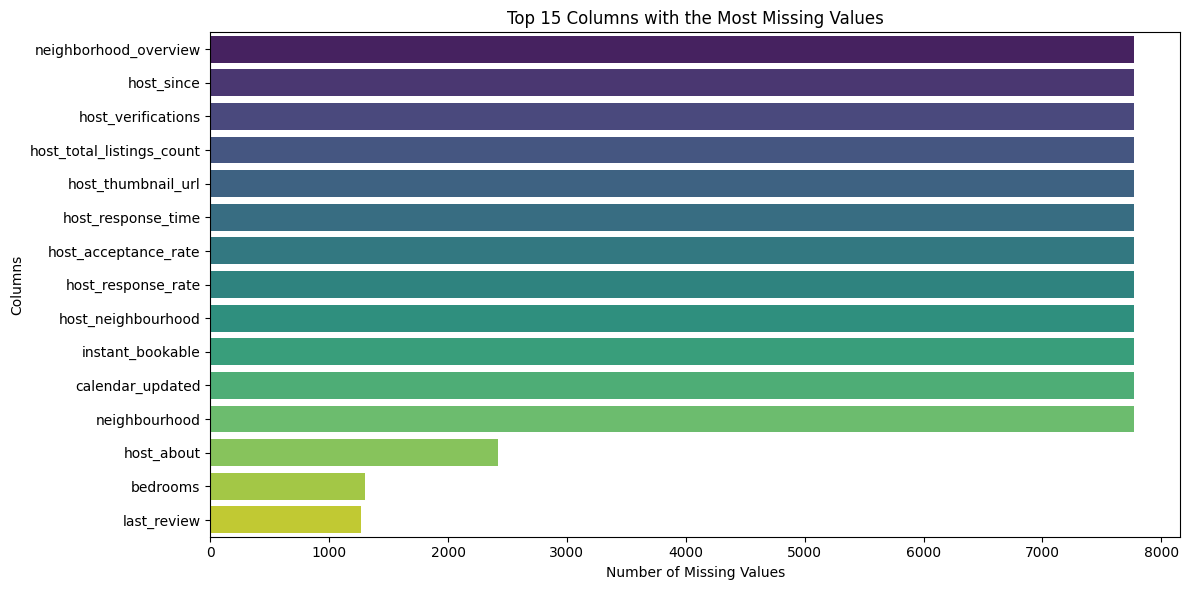

In [21]:

null_counts = df.isnull().sum()
missing_data = null_counts[null_counts > 0].sort_values(ascending=False)
print("Columns with missing values (Top 20):\n", missing_data.head(20))

plt.figure(figsize=(12, 6))
sns.barplot(x=missing_data.head(15).values, y=missing_data.head(15).index, palette='viridis')
plt.title('Top 15 Columns with the Most Missing Values')
plt.xlabel('Number of Missing Values')
plt.ylabel('Columns')
plt.tight_layout()
plt.show()

### Reflection:
1. What are the top 3 columns with the most missing values?
2. Which ones are likely to create business issues?
3. Which could be safely ignored or dropped?

### ✍️ Your Response: 🔧
1. The top three columns with the most missing values are neighborhood_overview, host_verificationsm and host_total_listings_count.


2. Host_verifications could create many business issues. When going through listings, customers want to be confident in what they are paying for, without host verifications, these listings can seem untrustworthly/fraudulent.

3. The last_review could be ignored or dropped, as long as the airbnb has other reviews/review accuracy, it can still be a trustworthly source for booking.


## 3. Drop Columns That Aren’t Useful

### Business framing:  

Not every column adds value. Analysts often remove columns that are too empty, irrelevant, or repetitive — especially when preparing data for others.

### Do the following:
Make a decision:

- Choose 2–4 columns to drop from your dataset
- Document your reasons for each one
- Confirm they're gone with `.head()` or `.info()`

In [22]:
# Drop specified columns
df = df.drop(columns=['last_review', 'calendar_updated'], errors='ignore')

# Confirm they are gone
print("Are 'last_review' or 'calendar_updated' in df?", any(col in df.columns for col in ['last_review', 'calendar_updated']))
df.head()

Are 'last_review' or 'calendar_updated' in df? False


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,1188641052152277018,https://www.airbnb.com/rooms/1188641052152277018,20260615212226,2026-06-16,city scrape,Spacious unit at heart of SEA,"Located in the heart of Seattle, This is a stu...",NaN,https://a0.muscache.com/pictures/miso/Hosting-...,32542619,...,NaN,NaN,NaN,NaN,NaN,4,4,0,0,NaN
1,849077848951991421,https://www.airbnb.com/rooms/849077848951991421,20260615212226,2026-06-16,city scrape,"Blueground | Central District, gym & bbq, nr d...",Feel at home wherever you choose to live with ...,NaN,https://a0.muscache.com/pictures/prohost-api/H...,107434423,...,NaN,NaN,NaN,NaN,NaN,239,239,0,0,NaN
2,599205596133828323,https://www.airbnb.com/rooms/599205596133828323,20260615212226,2026-06-16,city scrape,purple room,simple room facing front yard in centrally lo...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,48441443,...,5.00,5.00,5.00,NaN,NaN,5,0,5,0,0.06
3,846763,https://www.airbnb.com/rooms/846763,20260615212226,2026-06-16,city scrape,Right at Home in Ravenna,"Our home is a lovely peaceful place, and we wi...",NaN,https://a0.muscache.com/pictures/62990267/b8fe...,4421734,...,4.89,4.89,4.90,NaN,NaN,1,0,1,0,0.51
4,1512026480622905433,https://www.airbnb.com/rooms/1512026480622905433,20260615212226,2026-06-16,city scrape,"3 Min Walk to Capitol Hill Station, Brand New ...",Brand new 3BR/3BA townhome in the heart of Cap...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,44486963,...,4.94,4.89,4.94,STR-OPLI-25-004798,NaN,1,1,0,0,4.30


### Reflection:
1. Which columns did you drop?
2. Why were they not useful from a business perspective?
3. What could go wrong if you left them in?

### ✍️ Your Response: 🔧
1. I dropped last_review column and the calendar_updated column.

2. The last_review column that I mentioned before seems easy to safely ignore as there will be other reviews for airbnb. The calendar_updated column also had many missing values, I feel this column would be okay to be without as the information doesn't seem as important to customers.

3. If left in, it could create more issue of missing values with different charts. Getting rid of unecessary missing values will allow for more accurate information.



## 4. Fill or Fix Values in Key Columns

### Business framing:  

Let’s say your manager wants to see a map of listings with prices and review scores. If key fields are blank, the map won’t work. But not all missing values should be filled the same way.

### Do the following:
- Choose 2 columns with missing values
- Use a strategy to fill or flag those values
  - (e.g., median, “unknown”, forward-fill, or a placeholder)
- Explain what you did and why

In [23]:

bedrooms_median = df['bedrooms'].median()
df['bedrooms'] = df['bedrooms'].fillna(bedrooms_median)

#
rating_median = df['review_scores_rating'].median()
df['review_scores_rating'] = df['review_scores_rating'].fillna(rating_median)


print("Missing values in 'bedrooms':", df['bedrooms'].isnull().sum())
print("Missing values in 'review_scores_rating':", df['review_scores_rating'].isnull().sum())

Missing values in 'bedrooms': 0
Missing values in 'review_scores_rating': 0


### Reflection:
1. What two columns did you clean?
2. What method did you use for each, and why?
3. What risks are there in how you filled the data?

### ✍️ Your Response: 🔧
1. I cleaned the bedrooms column and the review_scores_rating column.

2. For both columns I used the median rating. I did this for both to keep scoring distribution consistent with the data.

3. Doing this could bring on some innaccurate information, but it will bring a better idea of how the airbnb's are usually like.


## 5. Convert and Clean Data Types

### Business framing:  

Sometimes columns that look like numbers are actually stored as text — which breaks calculations and slows down analysis. Common examples are price columns with dollar signs or availability stored as strings.

### Do the following:
- Identify one column with the wrong data type
- Clean and convert it into a usable format (e.g., from string to number)
- Check your work by summarizing or plotting the cleaned column

Original price type: object
0    $122.32
1        NaN
2     $68.30
3     $66.58
4    $540.00
Name: price, dtype: object

Cleaned price type: float64
count     6943.000000
mean       349.719676
std        465.813269
min         10.180000
25%        171.500000
50%        281.000000
75%        422.240000
max      25916.670000
Name: price, dtype: float64


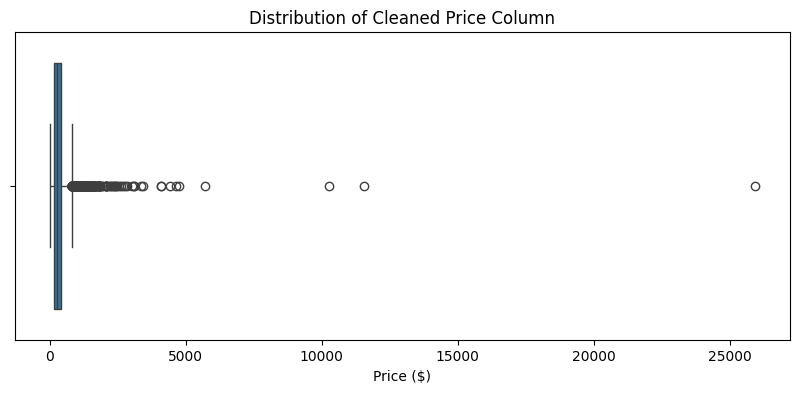

In [24]:

print("Original price type:", df['price'].dtype)
print(df['price'].head())

df['price'] = df['price'].astype(str).str.replace('$', '').str.replace(',', '')
df['price'] = pd.to_numeric(df['price'], errors='coerce')


print("\nCleaned price type:", df['price'].dtype)
print(df['price'].describe())

# Generate a boxplot of price to check work
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['price'].dropna())
plt.title('Distribution of Cleaned Price Column')
plt.xlabel('Price ($)')
plt.show()

### Reflection: :
1. What column did you fix?
2. What cleaning steps did you apply?
3. How does this help prepare the data for later use?

### ✍️ Your Response: 🔧
1. I fixed the price column. It was set as an object rather than a numeric formatting.

2. I made it a string data type. It includes distribution showing count, mean, std, etc.

3. This helps prepare the data to show how the pricing averages for each listing, this way customers can choose an airbnb within their price range.

## 6. Remove Duplicate Records

### Business framing:  

If a listing appears twice, it could inflate revenue estimates or confuse users. Airbnb needs each listing to be unique and accurate.

### Do the following:
- Check for rows that are exact duplicates
- If your data has an ID column and each ID is supposed to unique, then make sure there are no duplicate IDs
- Remove duplicates if found

In [27]:
exact_duplicates = df.duplicated().sum()
print(f"Number of exact duplicate rows: {exact_duplicates}")
duplicate_ids = df.duplicated(subset=['id']).sum()
print(f"Number of duplicate IDs: {duplicate_ids}")

if exact_duplicates > 0 or duplicate_ids > 0:
    df = df.drop_duplicates(subset=['id'], keep='first')
    print("Duplicates removed. New dataset shape:", df.shape)
else:
    print("No duplicates found. Dataset shape remains:", df.shape)

Number of exact duplicate rows: 0
Number of duplicate IDs: 0
No duplicates found. Dataset shape remains: (7769, 88)


### Reflection:
1. Did you find duplicates?
2. How did you decide what to drop or keep?
3. Why are duplicates risky for Airbnb teams?

### ✍️ Your Response: 🔧 🔧
1. Found duplicate data using the id column, removed any that had duplicate ids.

2. Any listings with duplicate id's could confuse the data and give innacurate information for averages and distribution.

3. Duplicates can be risky as they can possibly be spam/fraud in the airbnb systems. This will confuse the data analytics teams as it brings on inaccurate distributions.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 7**, where you'll perform data transformation techniques.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_6.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```





In [31]:
# Export the cleaned dataset to a CSV file
df.to_csv('cleaned_airbnb_data_6.csv', index=False)
print("Cleaned dataset successfully saved to 'cleaned_airbnb_data_6.csv'!")

Cleaned dataset successfully saved to 'cleaned_airbnb_data_6.csv'!


## 8. Final Reflection

You’ve just cleaned a real-world Airbnb dataset — the kind of work that happens every day in analyst and data science roles.

Before you move on to data transformation in Assignment 7, take a few moments to reflect on the decisions you made and what you learned.

### Reflection:
1. Which section of the assignment was the most challenging for you? What made it challenging? Was it the coding or the application of class concepts?
2. Look back at your assignment and discuss a time when you had to drop, fix, or keep a piece of data. Why was it necessary to drop, fix, or keep that specific piece of data? (e.x. dropping a column full of null values because it has no useful information)
3. What’s one way a business team (e.g., hosts, pricing analysts, app administrators) might benefit from the cleaned version of this data?
4. If you had more time, what would you explore or clean further?
5. How does this relate to your customized learning outcome you created in canvas?


Write your response clearly in full sentences. No more than a few sentences required per response.


### ✍️ Your Response: 🔧

1. Choosing which columns with missing values to drop was the most challenging for me, having to understand which columns would be the least important to keep in the data was hard to choose.  
2. It felt necessary to keep any columns that were important to the business. Such as host_verifications, even though there were so many missing values, this column is important to snuff out the possible fraudulent hosts on the site.  
3. When fixing the price column, the pricing analysts can have more accurate information of distribution of prices of airbnbs in this city.  
4. I would want to explore more missing data, and maybe find more columns that may be formatted incorrectly.
5. Understanding how to fix/fill missing data helps me understand what analysts in a business have to go through to keep up relevant/accurate information.  


## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_06_data_cleaning.ipynb"